# Data Analysis: Call Distribution Across Datasets

> Analyze the distribution of cell types across different datasets by processing all files in the `data/data-processed-nodes-with-harmonized-cell-types` directory.

In [1]:
import numpy as np
import pandas as pd
import os
import json
import requests
import shutil
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import normalize
import plotly.express as px

# NOTE: If you are using Plotly within the VS Code Notebook Editor you will need to add a line of code to ensure that your plots can be seen both within VS Code and when rendered to HTML by Quarto.
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook_connected" 

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# suppress warnings
import warnings
warnings.filterwarnings("ignore")   

In [2]:
basepath = "/u/yashjain/hra-cell-distance-analysis/data"
data_filedir = "data-processed-nodes-with-harmonized-cell-types"
figures_output_dir = "generated-figures"

In [3]:
# Function to load your data
def load_data(path):
    data = pd.read_csv(path)
    return data

In [4]:
# Function to read all files ending with "-nodes.csv" in the `data_filedir` directory into a single DataFrame. 
# An additional column `Tissue Type` is added to identify the dataset each row belongs to which comes from the subdirectory name in `data_filedir` that the file belongs to. 
# Another additional column `Dataset` is added to identify the dataset name which comes from the filename befrore the `-nodes.csv` suffix.
def read_all_datasets(basepath, data_filedir):
    all_files = []
    for subdir, dirs, files in os.walk(os.path.join(basepath, data_filedir)):
        for file in files:
            if file.endswith("-nodes.csv"):
                file_path = os.path.join(subdir, file)
                tissue_type = os.path.basename(subdir)
                dataset_name = file.replace("-nodes.csv", "")
                df = load_data(file_path)
                df['Tissue Type'] = tissue_type
                df['Dataset'] = dataset_name
                all_files.append(df)

    merged = pd.concat(all_files, ignore_index=True)
    # reset index after concatenation
    # merged.reset_index(drop=True, inplace=True)
    return merged

In [5]:
def create_directory(directory):
    if not os.path.exists(directory):
        os.makedirs(directory)
        print(f"Directory '{directory}' created successfully.")
    else:
        print(f"Directory '{directory}' already exists.")

In [6]:
print(len(os.listdir(os.path.join(basepath, data_filedir))))

14


In [7]:
# Create destination directory. Overwrite if it exists.
if os.path.exists(os.path.join(basepath, figures_output_dir)):
    shutil.rmtree(os.path.join(basepath, figures_output_dir))
    print(f"Directory '{figures_output_dir}' already exists and has been removed. New directory will be created.")
else:
    print(f"Directory '{figures_output_dir}' does not exist and will be created.")
os.makedirs(os.path.join(basepath, figures_output_dir), exist_ok=False)

Directory 'generated-figures' already exists and has been removed. New directory will be created.


## Per Dataset Cell Summary

In [7]:
# Call the function to read all datasets
df_all_data = read_all_datasets(basepath, data_filedir)

In [8]:
# Print the first few rows of the DataFrame
df_all_data.head(5)

,x,y,Original Cell Type,Level Three Cell Type,Level Three CL Label,Level Three CL ID,CL_Match/3,Level Two Cell Type,Level Two CL Label,Level Two CL ID,CL_Match/2,Level One Cell Type,Level One CL Label,Level One CL ID,CL_Match/1,Tissue Type,Dataset,z
0,1503.64128,1278.32154,NK,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford,B004_Ascending,NaN
1,1958.05496,1553.46072,NK,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford,B004_Ascending,NaN
2,2290.93940,1187.36332,NK,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford,B004_Ascending,NaN
3,2863.48554,891.08862,NK,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford,B004_Ascending,NaN
4,2563.43664,1468.54122,NK,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,natural killer cell,natural killer cell,CL:0000623,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford,B004_Ascending,NaN


In [9]:
# Print the total number of unique datasets per each tissue type
print("Total number of unique datasets per each tissue type:")
print(df_all_data.groupby('Tissue Type')['Dataset'].nunique())

# Print the sum of number of unique datasets overall.
print("\nTotal number of unique datasets overall:")
print(df_all_data['Dataset'].nunique())

Total number of unique datasets per each tissue type:
Tissue Type
bonemarrow-codex-chop                       20
colon-cycif-sorgerlab                       25
colon-xenium-stanford                       29
esophagus-codex-stanford                     1
intestine-codex-stanford                    64
lung-codex-urmc                              2
lymphnode-codex-yale                         5
maternalfetalinterface-mibitof-stanford    209
mouth-codex-czi                        13
pancreas-geomx-ufl                          12
skin-celldive-ge                            10
skin-confocal-sorgerlab                      2
spleen-codex-ufl                             6
tonsil-codex-stanford                        1
Name: Dataset, dtype: int64

Total number of unique datasets overall:
399


In [10]:
# Print the total number of cells per tissue type
print("Total number of cells per tissue type:")
tissue_counts = df_all_data.groupby('Tissue Type')['Original Cell Type'].count()
for tissue, count in tissue_counts.items():
	print(f"{tissue}: {count:,}")

# Print the sum of number of cells overall. Format the output number to be more readable.
print("\nTotal number of cells overall:")
print(f"{df_all_data['Original Cell Type'].count():,}")

Total number of cells per tissue type:
bonemarrow-codex-chop: 1,214,088
colon-cycif-sorgerlab: 12,758,141
colon-xenium-stanford: 2,639,215
esophagus-codex-stanford: 45,958
intestine-codex-stanford: 2,512,185
lung-codex-urmc: 1,209,309
lymphnode-codex-yale: 8,918,845
maternalfetalinterface-mibitof-stanford: 477,747
mouth-codex-czi: 1,412,189
pancreas-geomx-ufl: 14,891,875
skin-celldive-ge: 48,323
skin-confocal-sorgerlab: 55,255
spleen-codex-ufl: 992,398
tonsil-codex-stanford: 173,968

Total number of cells overall:
47,349,496


In [11]:
# Print the total number of unique cell types per tissue type. Compute separately for each cell type column (Level One Cell Type, Level Two Cell Type, Level Three Cell Type, Original Cell Type).
print("Total number of unique cell types per tissue type:")

# Create a summary table
tissue_types = df_all_data['Tissue Type'].unique()
columns = ['Original Cell Type', 'Level Three Cell Type', 'Level Two Cell Type', 'Level One Cell Type']

# Create a dictionary to store results
results = {}
for tissue in tissue_types:
    tissue_data = df_all_data[df_all_data['Tissue Type'] == tissue]
    results[tissue] = {}
    for col in columns:
        results[tissue][col] = tissue_data[col].nunique()

# Convert to DataFrame for better formatting
summary_df = pd.DataFrame(results).T
summary_df = summary_df[columns]  # Reorder columns

# Add a row for "Overall Unique Cell Types" which contains the total number of unique cell types across all tissue types from df_all_data for each column.
overall_unique = df_all_data[columns].nunique()
summary_df.loc['Total Unique Cell Types'] = overall_unique

summary_df

Total number of unique cell types per tissue type:


,Original Cell Type,Level Three Cell Type,Level Two Cell Type,Level One Cell Type
intestine-codex-stanford,25,25,17,5
tonsil-codex-stanford,10,10,8,5
esophagus-codex-stanford,12,12,11,5
colon-xenium-stanford,41,38,20,6
lymphnode-codex-yale,34,29,10,3
maternalfetalinterface-mibitof-stanford,26,23,11,5
mouth-codex-czi,39,28,20,6
pancreas-geomx-ufl,4,4,4,3
skin-celldive-ge,8,8,4,3
skin-confocal-sorgerlab,15,15,11,4


In [12]:
# Extract the following columns from df_all_data: Original Cell Type, Level Three Cell Type, Level Three CL Label, Level Three CL ID, CL_Match/3, Level Two Cell Type, Level Two CL Label, Level Two CL ID, CL_Match/2, Level One Cell Type, Level One CL Label, Level One CL ID, CL_Match/1.
# Create a table containing these columns but have the rows be unique combinations of these columns.

columns = [
    'Original Cell Type',
    'Level Three Cell Type',
    'Level Three CL Label',
    'Level Three CL ID',
    'CL_Match/3',
    'Level Two Cell Type',
    'Level Two CL Label',
    'Level Two CL ID',
    'CL_Match/2',
    'Level One Cell Type',
    'Level One CL Label',
    'Level One CL ID',
    'CL_Match/1',
    'Tissue Type',
]

# Extract the unique combinations of these columns from df_all_data. Sort the DataFrame by 'Level Three Cell Type' in ascending order.
unique_combinations = df_all_data[columns].drop_duplicates().sort_values(by='Level Three Cell Type', ascending=True)

unique_combinations.reset_index(drop=True, inplace=True)

unique_combinations


,Original Cell Type,Level Three Cell Type,Level Three CL Label,Level Three CL ID,CL_Match/3,Level Two Cell Type,Level Two CL Label,Level Two CL ID,CL_Match/2,Level One Cell Type,Level One CL Label,Level One CL ID,CL_Match/1,Tissue Type
0,Acinar Cells,acinar cell of salivary gland,acinar cell of salivary gland,CL:0002623,skos:exactMatch,gland epithelium cell,glandular secretory epithelial cell,CL:0000150,skos:exactMatch,epithelial cell,epithelial cell,CL:0000066,skos:exactMatch,mouth-codex-czi
1,Acini,acinar cell of salivary gland,acinar cell of salivary gland,CL:0002623,skos:exactMatch,gland epithelium cell,glandular secretory epithelial cell,CL:0000150,skos:exactMatch,epithelial cell,epithelial cell,CL:0000066,skos:exactMatch,mouth-codex-czi
2,Adipocytes,adipocyte,adipocyte,CL:0000136,skos:exactMatch,adipocyte,adipocyte,CL:0000136,skos:exactMatch,mesenchymal cell,mesenchymal cell,CL:0008019,skos:exactMatch,mouth-codex-czi
3,Adipocytes,adipocyte,adipocyte,CL:0000136,skos:exactMatch,adipocyte,adipocyte,CL:0000136,skos:exactMatch,mesenchymal cell,mesenchymal cell,CL:0008019,skos:exactMatch,colon-xenium-stanford
4,Adipocyte,adipocyte,adipocyte,CL:0000136,skos:exactMatch,adipocyte,adipocyte,CL:0000136,skos:exactMatch,mesenchymal cell,mesenchymal cell,CL:0008019,skos:exactMatch,bonemarrow-codex-chop
5,B-Cells,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,bonemarrow-codex-chop
6,B,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,tonsil-codex-stanford
7,B cell,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,lung-codex-urmc
8,B cells,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,colon-cycif-sorgerlab
9,B Cells,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,mouth-codex-czi


In [13]:
# Save unique_combinations DataFrame to a CSV file in the data/mapping_files directory.
unique_combinations.to_csv(os.path.join(basepath, "mapping_files", "generated_cell_type_complete_crosswalk.csv"), index=False)

In [14]:
# Print if there are any duplicates in the Original Cell Type column of the unique combinations DataFrame.
if unique_combinations['Original Cell Type'].duplicated().any():
    print("There are duplicates in the Original Cell Type column of the unique combinations DataFrame. This is expected because same Original Cell Type can be in multiple Tissue Types.")

# Print the duplicate values with their row indices.
duplicates = unique_combinations[unique_combinations['Original Cell Type'].duplicated(keep=False)]
duplicates

There are duplicates in the Original Cell Type column of the unique combinations DataFrame. This is expected because same Original Cell Type can be in multiple Tissue Types.


,Original Cell Type,Level Three Cell Type,Level Three CL Label,Level Three CL ID,CL_Match/3,Level Two Cell Type,Level Two CL Label,Level Two CL ID,CL_Match/2,Level One Cell Type,Level One CL Label,Level One CL ID,CL_Match/1,Tissue Type
2,Adipocytes,adipocyte,adipocyte,CL:0000136,skos:exactMatch,adipocyte,adipocyte,CL:0000136,skos:exactMatch,mesenchymal cell,mesenchymal cell,CL:0008019,skos:exactMatch,mouth-codex-czi
3,Adipocytes,adipocyte,adipocyte,CL:0000136,skos:exactMatch,adipocyte,adipocyte,CL:0000136,skos:exactMatch,mesenchymal cell,mesenchymal cell,CL:0008019,skos:exactMatch,colon-xenium-stanford
6,B,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,tonsil-codex-stanford
8,B cells,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,colon-cycif-sorgerlab
10,B cells,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,skin-confocal-sorgerlab
11,B,b cell,B cell,CL:0000236,skos:exactMatch,b cell,B cell,CL:0000236,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford
30,DC,dendritic cell,dendritic cell,CL:0000451,skos:exactMatch,dendritic cell,dendritic cell,CL:0000451,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,colon-xenium-stanford
32,DC,dendritic cell,dendritic cell,CL:0000451,skos:exactMatch,dendritic cell,dendritic cell,CL:0000451,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,maternalfetalinterface-mibitof-stanford
33,DC,dendritic cell,dendritic cell,CL:0000451,skos:exactMatch,dendritic cell,dendritic cell,CL:0000451,skos:exactMatch,immune cell,leukocyte,CL:0000738,skos:exactMatch,intestine-codex-stanford
43,Endothelial,endothelial cell,endothelial cell,CL:0000115,skos:exactMatch,endothelial cell,endothelial cell,CL:0000115,skos:exactMatch,endothelial cell,endothelial cell,CL:0000115,skos:exactMatch,lymphnode-codex-yale


## Heatmap for Cell Type Distribution at Different Levels of Cell Type Annotation Across Datasets 

In [15]:
# Method to create a heatmap visualization of cell type distribution across datasets.
def create_heatmap(df, normalize_method='percent', cell_type_level='Level Three Cell Type'):
    """
    Create an aesthetically enhanced heatmap visualization.
    """
    # Set the style and font
    plt.style.use("seaborn-v0_8-white") 
    plt.rcParams["svg.fonttype"] = 'none'  # to store text as text, not as path
    
    # Transpose the dataframe and sort index (cell types) alphabetically
    df_plot = df
    df_plot = df_plot.sort_index(axis=1)
    
    # Normalize the data
    if normalize_method == 'percent':
        df_plot = df_plot.div(df_plot.sum(axis=1), axis=0) * 100
    
    # Create binary mask for coloring
    binary_mask = (df_plot > 0).astype(float)
    
    # Calculate figure size
    width = max(16, len(df_plot.columns) * 0.4)
    height = max(8, len(df_plot.index) * 0.4)
    
    # Create figure with higher DPI for better quality
    fig, ax = plt.subplots(figsize=(width, height), dpi=150)
    
    # Define custom colors
    bg_color = '#ffffff'  # Pure white background
    present_color = '#D5A023'  # Professional blue, #D5A023
    absent_color = '#f8f9fa'  # Very light gray
    text_color = '#333333'  # Dark gray for text
    grid_color = '#e6e6e6'  # Light gray for grid
    
    # Set figure background color
    fig.patch.set_facecolor(bg_color)
    ax.set_facecolor(bg_color)
    
    # Create custom colormap
    custom_cmap = sns.color_palette([absent_color, present_color], n_colors=2)
    
    # Create annotations with custom formatting (float for non-zero, integer for zero)
    annotations = df_plot.copy()
    for i in range(len(annotations)):
        for j in range(len(annotations.columns)):
            val = annotations.iloc[i, j]
            if val == 0:
                annotations.iloc[i, j] = '0'
            else:
                annotations.iloc[i, j] = f'{val:.1f}'
    
    # Create heatmap with enhanced styling
    ax = sns.heatmap(binary_mask,
                     cmap=custom_cmap,
                     annot=annotations,
                     fmt='',
                     cbar=False,
                     linewidths=0.5,
                     linecolor=grid_color,
                     annot_kws={
                         'size': 7,
                         'color': text_color,
                         'ha': 'center',
                         'va': 'center'
                     },
                     square=True)
    
    # Style the axis labels with better positioning
    plt.xticks(rotation=90, color=text_color, ha='center', va='top')
    plt.yticks(rotation=0, color=text_color, va='center')
    
    # Enhance axis labels with adjusted positioning
    ax.set_xlabel(cell_type_level, fontsize=11, fontweight='bold', color=text_color, labelpad=15)
    ax.set_ylabel('Tissue Type', fontsize=11, fontweight='bold', color=text_color, labelpad=10)
    
    # Add title with styling
    plt.title('Cell Type Distribution Across Datasets', 
             pad=20,
             fontsize=13,
             fontweight='bold',
             color=text_color)
    
    # Remove spines
    for spine in ax.spines.values():
        spine.set_visible(False)
    
    # Adjust layout with specific margins
    plt.tight_layout(pad=1.5)
    
    # Save figure with high quality
    plt.savefig(f'{os.path.join(basepath, figures_output_dir)}/cell_type_distribution_binary_heatmap_{cell_type_level}.png',
                dpi=300,
                bbox_inches='tight',
                pad_inches=0.5,
                facecolor=bg_color)
    
    # Save fig as svg
    plt.savefig(f'{os.path.join(basepath, figures_output_dir)}/cell_type_distribution_binary_heatmap_{cell_type_level}.svg',
                dpi=600,
                bbox_inches='tight',
                pad_inches=0.5,
                facecolor=bg_color)
    plt.show()
    



Original Cell Type,AEC,AT1 _2,AT1_1,AT2,AT2_1,AT2_2,AT2_p,Acinar Cells,Acini,Adipo-MSC,Adipocyte,Adipocytes,Artifact,Autofluorescent,B,B Cells,B cell,B cells,"B cells, red pulp",B-Cells,B_Cycling,B_GC_DZ,B_GC_LZ,B_GC_prePB,B_IFN,B_activated,B_cell_1,B_cell_macrophage_p?,B_mem,B_naive,B_plasma,B_preGC,Basal Keratincytes,Best4+ Enterocytes,Beta cell,CAP_ENDO,CD11B+ CD11C- cells,CD34+ CD61+,CD4 Memory T cells,CD4 T,CD4 T Cells,CD4+,CD4+ T cell,CD4+ T-Cell,CD4+_T_cell_1,CD4+_T_cell_2,CD4+_T_cell_3,CD44+ Undetermined,CD4T,CD4_+_Tcell/macrophage,CD57+ Enterocyte,CD66+ Enterocyte,CD68,CD7+ Immune,CD8 + T cell_1,CD8 Memory T cells,CD8 T,CD8 T Cells,CD8+,CD8+ T,CD8+ T cell_2,CD8+ T-Cell,CD8+_T_cell_1,CD8+_T_cell_2,CD8+_T_cell_3,CD8+_T_cell_CD_4+_T_cell,CD8T,CLP,Cancer Associated Fibroblasts,Crypt Fibroblasts 1,Crypt Fibroblasts 2,Crypt Fibroblasts 3,Crypt Fibroblasts 4,Cycling TA,CyclingTA,DC,DC_CCR7+,DC_cDC1,DC_cDC2,DC_pDC,DDB2,DN Lymphocyte,DP,DP Lymphocyte,Dendritic Cells,Dendritic cells,Ductal Epithelial Cells,Ductal cell,Ducts,ENDO_1,ENDO_CD8+_T_Cell,ENDO_SMC,EVT1a,EVT1b,EVT1c,EVT2,Early Myeloid Progenitor,Endo_2,Endo_p,Endosteal,Endothelial,Enterocyte,Enterocyte Progenitors,Enterocytes,Enteroendocrine,Epithelial,Erythroblast,Erythroid,FDC,Fibroblasts,Fol B cells,GATA1neg_Mks,GATA1pos_Mks,GC,GMP,GMP/Myeloblast,Glandular,Glandular_epi,Glia,Glial/Neuron,Goblet,HSC,HSPC,ICC,ILC,ILCs,Immature Enterocytes,Immature Goblet,Immature_B_Cell,Innate,Intermediate Myeloid,Ionocytes,KI67,Keratinocyte,Ki67 proliferating,Ki67+ Tumor/Epithelial,Langerhan cells,Langerhans Cells,Leukocyte,Lung_Epithelial_1,Lung_Epithelial_4,Lung_Epithelial_p,Lung_Epithelil_2_CD4+_T_cell,Lymphatic,Lymphatic Endothelial Cells,Lymphatic Vascular Cells,Lymphatic endothelial cells,Lymphatic_Endothelium,Lymphocyte(III),M1 Macrophage,M2 Macrophage,MEP/Early Erythroblast,MUC1+ Enterocyte,Mac1a,Mac1b,Mac2a,Mac2b,Mac2c,Macrophage,Macrophage(I),Macrophage(II),Macrophage(III),Macrophage(IV),Macrophages,Macrophages_M1,Macrophages_M2,Mast,Mast Cells,Mast cell,Mature Myeloid,Melanocytes,Memory B,Merkel Cells,Monocyte-Macrophage,Monocytes,Mural Cells,Muscle/Fibroblast,Myeloid,Myeloid cells,Myoepithelial Cells,Myofibroblasts,Myofibroblasts/Smooth Muscle 1,Myofibroblasts/Smooth Muscle 2,Myofibroblasts/Smooth Muscle 3,NK,NK Cells,NK1,NK2,NK3,NK4,NKT,NPM1 Mutant Blast,Naive B,Naive T,Nerve,Neuroendocrine,Neurons,Neutrophil,Neutrophils,Neutrophils/Monocytes,Non-Classical Monocyte,Other,Other Immune,Others,P53,PD1+ T helper,PD1+ Tc,PDL1+ Macrophage,PDL1+ Tumor/Epithelial,PDL1+ lymphocyte,PDPN,Paneth,Pericytes,Placental_Mac,Plasma,Plasma Cells,Podoplanin,SEC,SMC_1,SMC_2,SPINK2+ HSPC,Schwann Cells,Secretory_epithelial,Sinusoidal cells,Skeletal Myocytes,Smooth muscle,SmoothMuscle,Squamous_epithelial,Stem,Stroma,Suprabasal Keratinocytes,T,T helper,T reg,T-Helper,T-Killer,T-Reg,TA,TA1,TA2,THY1+ MSC,T_CD4+,T_CD4+_TfH,T_CD4+_TfH_GC,T_CD4+_naive,T_CD8+_CD161+,T_CD8+_cytotoxic,T_CD8+_naive,T_TIM3+,T_TfR,T_Treg,Tc,Tc cell,Th,Tissue T,Treg,Tregs,Tuft,Tumor,Tumor/Epithelial,UNK_1,UNK_1_APC,UNK_2,UNK_3,UNK_3_(col1a1-driven_cluster),UNK_4_(col1a1_driven_cluster),UNK_5_ambiguous,Undetermined,Unknown,Unknown_lowcount,VEC Progen,VSMC,Vascular Endothelial Cells,Villus Fibroblasts WNT5B+,blood endothelial,gd T Cells,indistinct,keratinocytes,lung Intersitial macrophage,lymphatic Endothelium,macrophage,macrophage_2,macrophage_3,macrophage_CD1c+_myeloidDC,macrophage_p,megakaryocyte,muscle,myofibroblast,neutrophil,neutrophil_2,other,pDC,smooth muscle 1,smooth muscle_2,unknown
Tissue Type,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
bonemarrow-codex-chop,7127,0,0,0,0,0,0,0,0,7967,23798,0,28818,40530,0,0,0,0,0,67639,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,387,0,0,0,0,0,401

In [16]:
heatmap_df_loriginal = df_all_data.groupby(['Tissue Type', 'Original Cell Type']).size().unstack(fill_value=0)
# Create a heatmap of the summary DataFrame
create_heatmap(heatmap_df_loriginal, normalize_method='percent', cell_type_level='Original Cell Type')
heatmap_df_loriginal

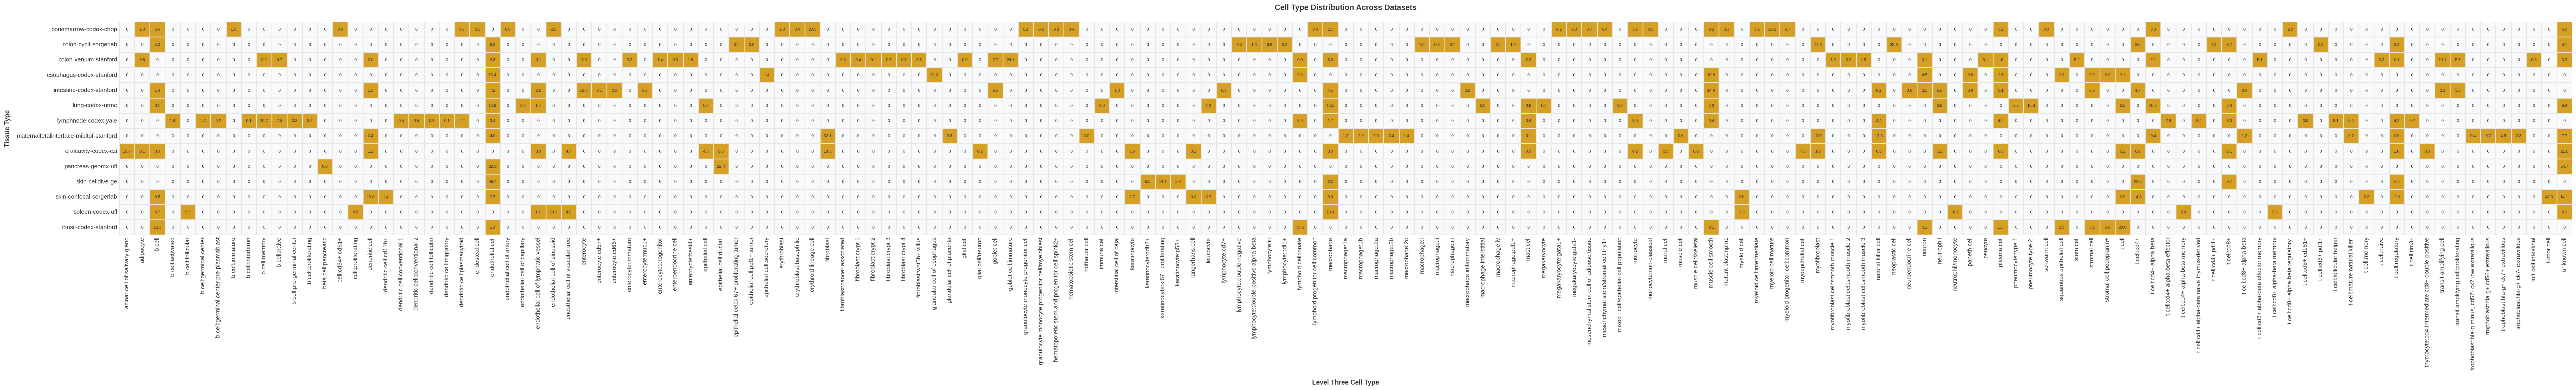

Level Three Cell Type,acinar cell of salivary gland,adipocyte,b cell,b cell:activated,b cell:follicular,b cell:germinal center,b cell:germinal center pre-plasmablast,b cell:immature,b cell:interferon,b cell:memory,b cell:naive,b cell:pre-germinal center,b cell:proliferating,beta cell:pancreatic,cell:cd34+ cd61+,cell:proliferating,dendritic cell,dendritic cell:cd11b+,dendritic cell:conventional 1,dendritic cell:conventional 2,dendritic cell:follicular,dendritic cell:migratory,dendritic cell:plasmacytoid,endosteal cell,endothelial cell,endothelial cell of artery,endothelial cell of capillary,endothelial cell of lymphatic vessel,endothelial cell of sinusoid,endothelial cell of vascular tree,enterocyte,enterocyte:cd57+,enterocyte:cd66+,enterocyte:immature,enterocyte:muc1+,enterocyte:progenitor,enteroendocrine cell,enteroycte:best4+,epithelial cell,epithelial cell:ductal,epithelial cell:ki67+ proliferating tumor,epithelial cell:pdl1+ tumor,epithelial cell:secretory,erythroblast,erythroblast:basophilic,erythroid lineage cell,fibroblast,fibroblast:cancer associated,fibroblast:crypt 1,fibroblast:crypt 2,fibroblast:crypt 3,fibroblast:crypt 4,fibroblast:wnt5b+ villus,glandular cell of esophagus,glandular cell of placenta,glial cell,glial cell/neuron,goblet cell,goblet cell:immature,granulocyte monocyte progenitor cell,granulocyte monocyte progenitor cell/myeloblast,hematopoietic stem and progenitor cell:spink2+,hematopoietic stem cell,hofbauer cell,immune cell,interstitial cell of cajal,keratinocyte,keratinocyte:ddb2+,keratinocyte:ki67+ proliferating,keratinocyte:p53+,langerhans cell,leukocyte,lymphocyte:cd7+,lymphocyte:double-negative,lymphocyte:double-positive alpha-beta,lymphocyte:iii,lymphocyte:pdl1+,lymphoid cell:innate,lymphoid progenitor cell:common,macrophage,macrophage:1a,macrophage:1b,macrophage:2a,macrophage:2b,macrophage:2c,macrophage:i,macrophage:ii,macrophage:iii,macrophage:inflammatory,macrophage:interstitial,macrophage:iv,macrophage:pdl1+,mast cell,megakaryocyte,megakaryocyte:gata1+,megakaryocyte:gata1-,mesenchymal stem cell of adipose tissue,mesenchymal stem/stromal cell:thy1+,mixed t cell/epithelial cell population,monocyte,monocyte:non-classical,mural cell,muscle cell,muscle cell:skeletal,muscle cell:smooth,mutant blast:npm1,myeloid cell,myeloid cell:intermediate,myeloid cell:mature,myeloid progenitor cell:common,myoepithelial cell,myofibroblast,myofibroblast cell:smooth muscle 1,myofibroblast cell:smooth muscle 2,myofibroblast cell:smooth muscle 3,natural killer cell,neoplastic cell,neuroendocrine cell,neuron,neutrophil,neutrophil/monocyte,paneth cell,pericyte,plasma cell,pneumocyte:type 1,pneumocyte:type 2,schwann cell,squamous epithelial cell,stem cell,stromal cell,stromal cell:podoplanin+,t cell,t cell:cd4+,t cell:cd4+ alpha-beta,t cell:cd4+ alpha-beta effector,t cell:cd4+ alpha-beta memory,t cell:cd4+ alpha-beta naive thymus-derived,t cell:cd4+ pdl1+,t cell:cd8+,t cell:cd8+ alpha-beta,t cell:cd8+ alpha-beta effector memory,t cell:cd8+ alpha-beta memory,t cell:cd8+ alpha-beta regulatory,t cell:cd8+ cd161+,t cell:cd8+ pdl1+,t cell:follicular helper,t cell:mature natural killer,t cell:memory,t cell:naive,t cell:regulatory,t cell:tim3+,thymocyte:cd4-intermediate cd8+ double-positive,transit amplifying cell,transit amplifying cell:proliferating,"trophoblast:hla-g minus, cd57- ck7 low extravillous",trophoblast:hla-g+ cd56+ extravillous,trophoblast:hla-g+ ck7+ extravillous,trophoblast:hla-g+ ck7- extravillous,tuft cell:intestinal,tumor cell,unknown cell
Tissue Type,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
bonemarrow-codex-chop,0,23798,67639,0,0,0,0,11874,0,0,0,0,0,0,387,0,0,0,0,0,0,0,8800,4026,0,7127,0,0,24640,0,0,0,0,0,0,0,0,0,0,0,0,0,0,23866,558,253710,0,0,0,0,0,0,0,0,0,0,0,0,0,945,1960,2250,5191,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,165,27731,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2635,3649,7967,4846,0,46785,6218,0,0,

In [17]:
heatmap_df_l3 = df_all_data.groupby(['Tissue Type', 'Level Three Cell Type']).size().unstack(fill_value=0)
# Create a heatmap of the summary DataFrame
create_heatmap(heatmap_df_l3, normalize_method='percent', cell_type_level='Level Three Cell Type')
heatmap_df_l3


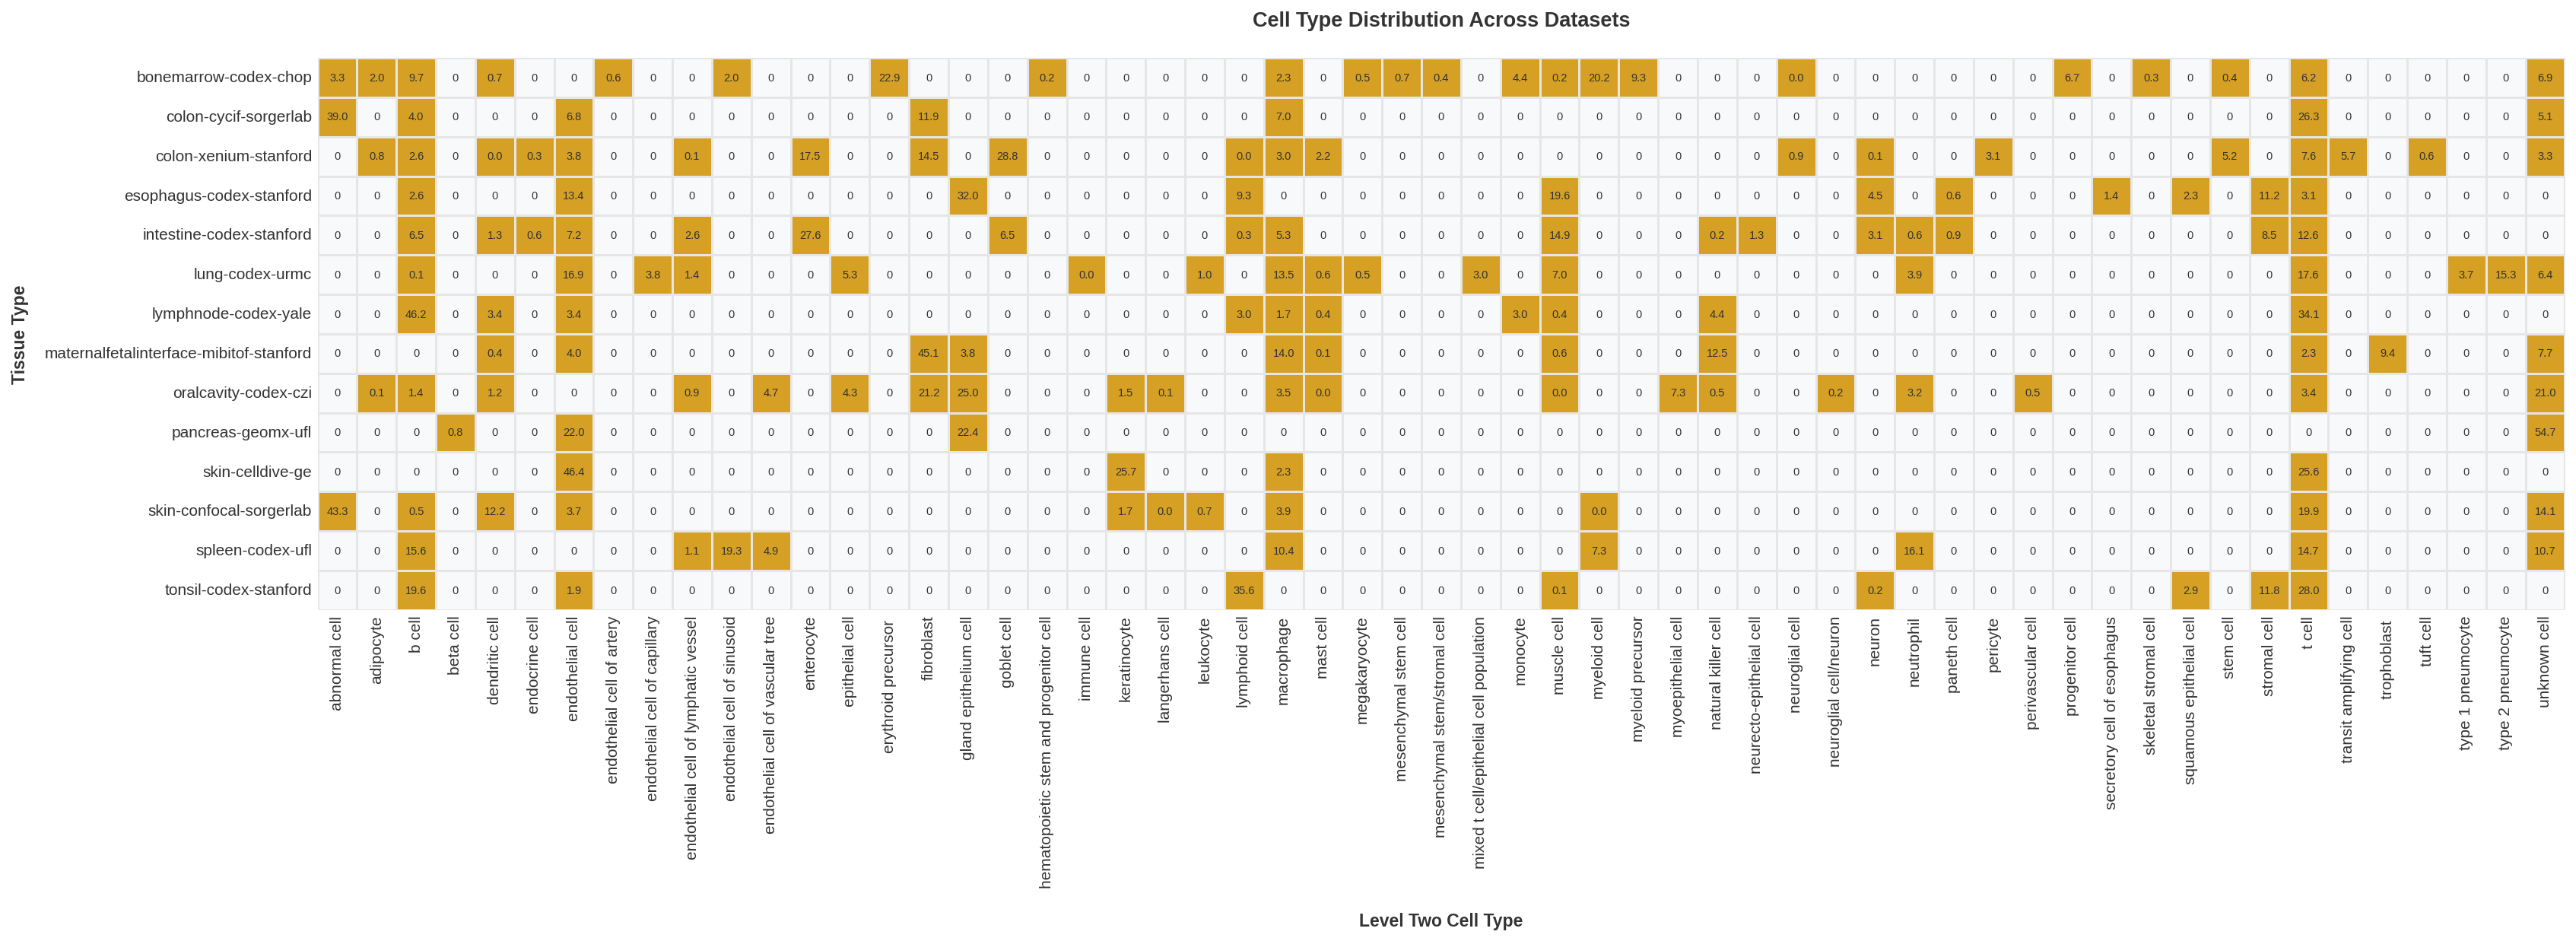

Level Two Cell Type,abnormal cell,adipocyte,b cell,beta cell,dendritic cell,endocrine cell,endothelial cell,endothelial cell of artery,endothelial cell of capillary,endothelial cell of lymphatic vessel,endothelial cell of sinusoid,endothelial cell of vascular tree,enterocyte,epithelial cell,erythroid precursor,fibroblast,gland epithelium cell,goblet cell,hematopoietic stem and progenitor cell,immune cell,keratinocyte,langerhans cell,leukocyte,lymphoid cell,macrophage,mast cell,megakaryocyte,mesenchymal stem cell,mesenchymal stem/stromal cell,mixed t cell/epithelial cell population,monocyte,muscle cell,myeloid cell,myeloid precursor,myoepithelial cell,natural killer cell,neurecto-epithelial cell,neuroglial cell,neuroglial cell/neuron,neuron,neutrophil,paneth cell,pericyte,perivascular cell,progenitor cell,secretory cell of esophagus,skeletal stromal cell,squamous epithelial cell,stem cell,stromal cell,t cell,transit amplifying cell,trophoblast,tuft cell,type 1 pneumocyte,type 2 pneumocyte,unknown cell
Tissue Type,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
bonemarrow-codex-chop,39861,23798,118366,0,8800,0,0,7127,0,0,24640,0,0,0,278134,0,0,0,2250,0,0,0,0,0,27731,0,6671,7967,4846,0,53003,2939,245083,113262,0,0,0,52,0,0,0,0,0,0,81747,0,4026,0,5191,0,75200,0,0,0,0,0,83394
colon-cycif-sorgerlab,4970579,0,513904,0,0,0,870316,0,0,0,0,0,0,0,0,1517623,0,0,0,0,0,0,0,0,888784,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3352610,0,0,0,0,0,644325
colon-xenium-stanford,0,19998,68098,0,280,8859,100459,0,0,1678,0,0,461856,0,0,383041,0,760776,0,0,0,0,0,21,79329,57344,0,0,0,0,0,0,0,0,0,0,0,23129,0,1632,0,0,82636,0,0,0,0,0,136725,0,201084,150379,0,15315,0,0,86576
esophagus-codex-stanford,0,0,1177,0,0,0,6181,0,0,0,0,0,0,0,0,0,14690,0,0,0,0,0,0,4282,0,0,0,0,0,0,0,9023,0,0,0,0,0,0,0,2047,0,275,0,0,0,658,0,1077,0,5132,1416,0,0,0,0,0,0
intestine-codex-stanford,0,0,163826,0,32002,14970,180762,0,0,64498,0,0,694171,0,0,0,0,163170,0,0,0,0,0,7174,134303,0,0,0,0,0,0,375143,0,0,0,5027,33832,0,0,76903,14657,21381,0,0,0,0,0,0,0,212937,317429,0,0,0,0,0,0
lung-codex-urmc,0,0,1314,0,0,0,204947,0,46307,17253,0,0,0,64678,0,0,0,0,0,10,0,0,12297,0,163233,7495,5595,0,0,36072,0,84712,0,0,0,0,0,0,0,0,46560,0,0,0,0,0,0,0,0,0,212505,0,0,0,44182,185250,76899
lymphnode-codex-yale,0,0,4121192,0,307086,0,303403,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,267761,150671,39333,0,0,0,0,263671,32155,0,0,0,390251,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3043322,0,0,0,0,0,0
maternalfetalinterface-mibitof-stanford,0,0,0,0,1831,0,19045,0,0,0,0,0,0,0,0,215676,18065,0,0,0,0,0,0,0,66750,678,0,0,0,0,0,3084,0,0,0,59780,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11205,0,45044,0,0,0,36589
mouth-codex-czi,0,1357,19603,0,17028,0,0,0,0,12820,0,66969,0,61383,0,299164,353051,0,0,0,20805,1421,0,0,49384,576,0,0,0,0,0,490,0,0,102636,6936,0,0,2525,0,45147,0,0,6807,0,0,0,0,0,0,47701,0,0,0,0,0,296386


In [18]:
heatmap_df_l2 = df_all_data.groupby(['Tissue Type', 'Level Two Cell Type']).size().unstack(fill_value=0)
# Create a heatmap of the summary DataFrame
create_heatmap(heatmap_df_l2, normalize_method='percent', cell_type_level='Level Two Cell Type')
heatmap_df_l2

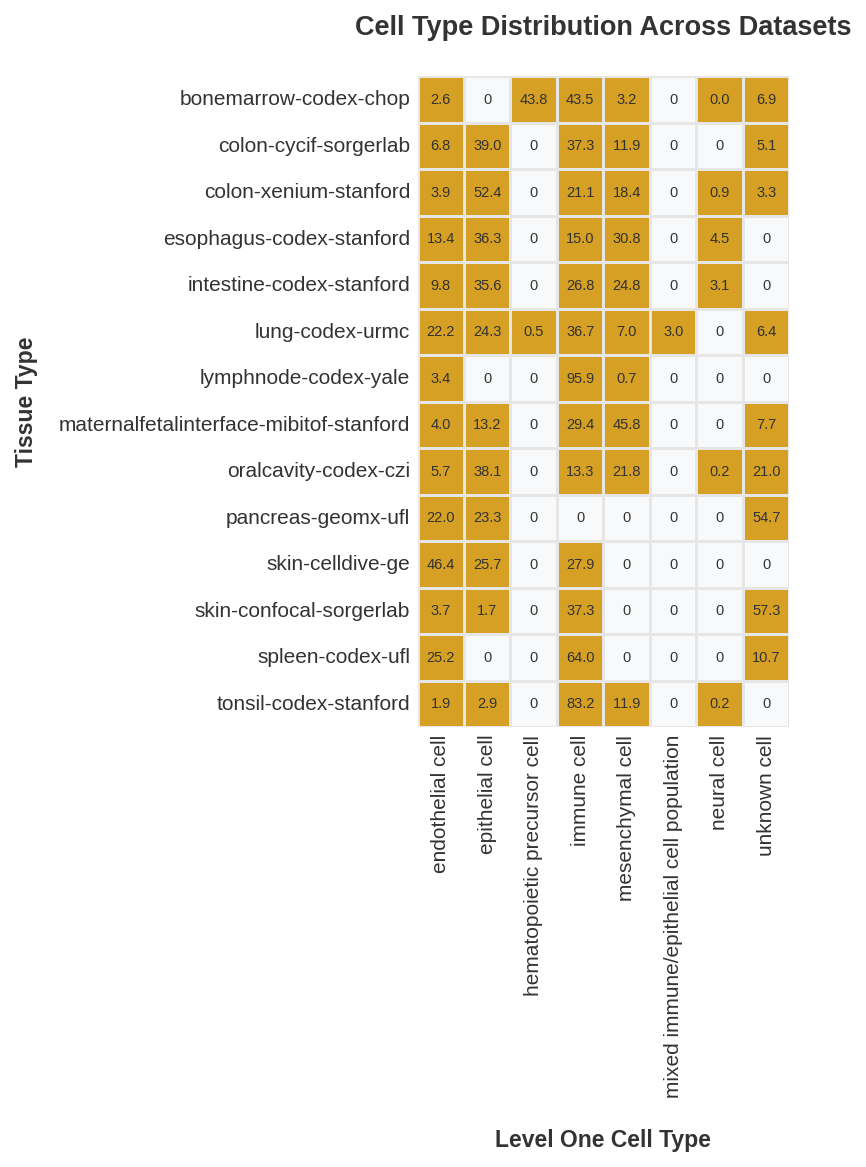

Level One Cell Type,endothelial cell,epithelial cell,hematopoietic precursor cell,immune cell,mesenchymal cell,mixed immune/epithelial cell population,neural cell,unknown cell
Tissue Type,,,,,,,,
bonemarrow-codex-chop,31767,0,531962,528183,38730,0,52,83394
colon-cycif-sorgerlab,870316,4970579,0,4755298,1517623,0,0,644325
colon-xenium-stanford,102137,1383531,0,556535,485675,0,24761,86576
esophagus-codex-stanford,6181,16700,0,6875,14155,0,2047,0
intestine-codex-stanford,245260,893692,0,674418,621912,0,76903,0
lung-codex-urmc,268507,294110,5595,443414,84712,36072,0,76899
lymphnode-codex-yale,303403,0,0,8556416,59026,0,0,0
maternalfetalinterface-mibitof-stanford,19045,63109,0,140244,218760,0,0,36589
mouth-codex-czi,79789,537875,0,187796,307818,0,2525,296386


In [19]:
heatmap_df_l1 = df_all_data.groupby(['Tissue Type', 'Level One Cell Type']).size().unstack(fill_value=0)
# Create a heatmap of the summary DataFrame
create_heatmap(heatmap_df_l1, normalize_method='percent', cell_type_level='Level One Cell Type')
heatmap_df_l1

## Bar Distribution of cell types across datasets

In [20]:
def create_bar_distribution_plot (df, cell_type_level='Original Cell Type', log_scale=True):
    # Count the occurrences of each cell type
    cell_type_counts = df[cell_type_level].value_counts()
    plt.rcParams["svg.fonttype"] = 'none'  # to store text as text, not as path

    # Create a bar plot using plotly
    fig = px.bar(x=cell_type_counts.index, 
                y=cell_type_counts.values,
                log_y=log_scale,  # Use log scale for y-axis
                # color=cell_type_counts.values,
                color_continuous_scale='golden',
                color_discrete_sequence=['#D5A023'], 
                title='Distribution of Cell Types Across All Datasets',
                labels={'x': 'Cell Type', 'y': 'Count'},
                template='plotly_white')

    y_axis_title = 'Count (log scale)' if log_scale else 'Count'

    # Update layout
    fig.update_layout(
        showlegend=False,
        xaxis_tickangle=270,
        height=600,
        width=1200,
        margin=dict(b=150),  # Increase bottom margin for long labels
        xaxis_title=cell_type_level,
        yaxis_title=y_axis_title,
        title_x=0.5,  # Center the title
        # yaxis=dict(type='log')  # Use log scale for better visualization
    )
    
    # Adjust layout with specific margins
    plt.tight_layout(pad=1.5)

    
    # Save figure with high quality
    plt.savefig(f'{os.path.join(basepath, figures_output_dir)}/cell_type_distribution_bar_plot_{cell_type_level}.png',
                dpi=300,
                bbox_inches='tight',
                pad_inches=0.5,
                # facecolor=bg_color
                )
    
    # Save fig as svg
    plt.savefig(f'{os.path.join(basepath, figures_output_dir)}/cell_type_distribution_bar_plot_{cell_type_level}.svg',
                dpi=600,
                bbox_inches='tight',
                pad_inches=0.5,
                # facecolor=bg_color
                )

    fig.show()

In [21]:
create_bar_distribution_plot(df_all_data, cell_type_level='Original Cell Type', log_scale=True)

<Figure size 640x480 with 0 Axes>

In [22]:
create_bar_distribution_plot(df_all_data, cell_type_level='Level Three Cell Type', log_scale=True)

<Figure size 640x480 with 0 Axes>

In [23]:
create_bar_distribution_plot(df_all_data, cell_type_level='Level Two Cell Type', log_scale=True)

<Figure size 640x480 with 0 Axes>

In [24]:
create_bar_distribution_plot(df_all_data, cell_type_level='Level One Cell Type', log_scale=True)

<Figure size 640x480 with 0 Axes>

In [25]:
create_bar_distribution_plot(df_all_data, cell_type_level='Level One Cell Type', log_scale=False)

<Figure size 640x480 with 0 Axes>

## Donut Chart of Cell Type Distribution 

In [26]:
def create_donut_chart_datasets_per_tissue(df):
    """
    Create a donut chart showing the distribution of unique datasets per tissue type.
    """
    # Get the data for the chart
    datasets_per_tissue = df.groupby('Tissue Type')['Dataset'].nunique().sort_values(ascending=False)
    
    # Create the donut chart using plotly
    fig = px.pie(
        values=datasets_per_tissue.values,
        names=datasets_per_tissue.index,
        title='Distribution of Unique Datasets per Tissue Type',
        hole=0.4,  # Creates the donut hole
        color_discrete_sequence=px.colors.qualitative.Set3
    )
    
    # Update layout for better appearance
    fig.update_layout(
        title_x=0.5,  # Center the title
        font=dict(size=12),
        showlegend=True,
        legend=dict(
            orientation="v",
            yanchor="middle",
            y=0.5,
            xanchor="left",
            x=1.05
        ),
        width=800,
        height=600,
        template='plotly_white'
    )
    
    # Update traces to show both percentage and count
    fig.update_traces(
        textposition='inside',
        textinfo='label+percent+value',  # Show label, percentage, and count
        textfont_size=9,  # Slightly smaller font to fit more text
        texttemplate='%{label}<br>%{percent}<br>(%{value})',  # Custom format with count
        marker=dict(line=dict(color='white', width=2))
    )
    
    # Add annotation in the center of the donut
    total_datasets = datasets_per_tissue.sum()
    fig.add_annotation(
        text=f"Total<br>{total_datasets}<br>Datasets",
        x=0.5, y=0.5,
        font_size=16,
        font_color="black",
        showarrow=False
    )
    
    # Save the figure
    fig.write_image(f'{os.path.join(basepath, figures_output_dir)}/datasets_per_tissue_donut_chart.png',
                    width=800, height=600, scale=2)
    fig.write_image(f'{os.path.join(basepath, figures_output_dir)}/datasets_per_tissue_donut_chart.svg',
                    width=800, height=600)
    
    # Show the chart
    fig.show()
    
    # Also print the underlying data
    print("Total number of unique datasets per each tissue type:")
    for tissue, count in datasets_per_tissue.items():
        print(f"{tissue}: {count}")
    print(f"\nTotal datasets across all tissues: {total_datasets}")

# Call the function
create_donut_chart_datasets_per_tissue(df_all_data)

Total number of unique datasets per each tissue type:
maternalfetalinterface-mibitof-stanford: 209
intestine-codex-stanford: 64
colon-xenium-stanford: 29
colon-cycif-sorgerlab: 25
bonemarrow-codex-chop: 20
mouth-codex-czi: 13
pancreas-geomx-ufl: 12
skin-celldive-ge: 10
spleen-codex-ufl: 6
lymphnode-codex-yale: 5
skin-confocal-sorgerlab: 2
lung-codex-urmc: 2
esophagus-codex-stanford: 1
tonsil-codex-stanford: 1

Total datasets across all tissues: 399


In [27]:
def create_donut_chart_cells_per_tissue(df):
    """
    Create a donut chart showing the distribution of total cells per tissue type.
    """
    # Get the data for the chart
    cells_per_tissue = df.groupby('Tissue Type')['Original Cell Type'].count().sort_values(ascending=False)
    
    # Create the donut chart using plotly
    fig = px.pie(
        values=cells_per_tissue.values,
        names=cells_per_tissue.index,
        title='Distribution of Total Cells per Tissue Type',
        hole=0.4,  # Creates the donut hole
        color_discrete_sequence=px.colors.qualitative.Set3
    )
    
    # Update layout for better appearance
    fig.update_layout(
        title_x=0.5,  # Center the title
        font=dict(size=12),
        showlegend=True,
        legend=dict(
            orientation="v",
            yanchor="middle",
            y=0.5,
            xanchor="left",
            x=1.05
        ),
        width=800,
        height=600,
        template='plotly_white'
    )
    
    # Update traces to show both percentage and count
    fig.update_traces(
        textposition='inside',
        textinfo='label+percent+value',  # Show label, percentage, and count
        textfont_size=9,  # Slightly smaller font to fit more text
        texttemplate='%{label}<br>%{percent}<br>(%{value:,})',  # Custom format with count
        marker=dict(line=dict(color='white', width=2))
    )
    
    # Add annotation in the center of the donut
    total_cells = cells_per_tissue.sum()
    fig.add_annotation(
        text=f"Total<br>{total_cells:,}<br>Cells",
        x=0.5, y=0.5,
        font_size=16,
        font_color="black",
        showarrow=False
    )
    
    # Save the figure
    fig.write_image(f'{os.path.join(basepath, figures_output_dir)}/cells_per_tissue_donut_chart.png',
                    width=800, height=600, scale=2)
    fig.write_image(f'{os.path.join(basepath, figures_output_dir)}/cells_per_tissue_donut_chart.svg',
                    width=800, height=600)
    
    # Show the chart
    fig.show()
    
    # Also print the underlying data
    print("Total number of cells per tissue type:")
    for tissue, count in cells_per_tissue.items():
        print(f"{tissue}: {count:,}")
    print(f"\nTotal cells across all tissues: {total_cells:,}")

# Call the function
create_donut_chart_cells_per_tissue(df_all_data)

Total number of cells per tissue type:
pancreas-geomx-ufl: 14,891,875
colon-cycif-sorgerlab: 12,758,141
lymphnode-codex-yale: 8,918,845
colon-xenium-stanford: 2,639,215
intestine-codex-stanford: 2,512,185
mouth-codex-czi: 1,412,189
bonemarrow-codex-chop: 1,214,088
lung-codex-urmc: 1,209,309
spleen-codex-ufl: 992,398
maternalfetalinterface-mibitof-stanford: 477,747
tonsil-codex-stanford: 173,968
skin-confocal-sorgerlab: 55,255
skin-celldive-ge: 48,323
esophagus-codex-stanford: 45,958

Total cells across all tissues: 47,349,496
